In [1]:
#!/usr/bin/env python
# coding: utf-8

# In[1]:


# JPK qi data to text file in .xyzc format conversion program
# command format: qi2txt input_file output_file
# input_file: name of the input file (including its path if necessary)
# output_file: name of the output file (including its path if necessary)

import zipfile
import io
import numpy as np
import struct
import matplotlib.pyplot as plt
import re
import time
import sys
import pandas as pd
from scipy import interpolate


# 入出力ファイルのパスを取得
QI_FILES = ["qi1.jpk-qi-data", "qi2.jpk-qi-data", "qi3.jpk-qi-data", "qi4.jpk-qi-data", "qi5.jpk-qi-data", "qi6.jpk-qi-data", "qi7.jpk-qi-data", "qi8.jpk-qi-data"]
ANS_FILES = ["qi1.txt", "qi2.txt", "qi3.txt", "qi4.txt", "qi5.txt", "qi6.txt", "qi7.txt", "qi8.txt"]
N_Z_PTS = 256
fcs = []
ans = []
n_pts_max = 0

start_time = time.perf_counter()

for f_num, file in enumerate(QI_FILES):
    print("Reading data from " + file)

    with zipfile.ZipFile(file) as zf:
        # shared-data/header.propertiesからのパラメータの読み込み
        with zf.open("shared-data/header.properties") as f:
            f.readline()
            sh_param = {}
            for b_line in f:
                s_line = b_line.decode("utf-8")
                m = re.search("=",s_line)
                sh_param[s_line[:m.end()-1]]=s_line[m.end():]

        # channelの名前と番号の辞書を作成
        ch = {}
        i = 0
        while True:
            try:
                ch_name=sh_param["lcd-info."+str(i)+".channel.name"][:-1]
                ch[ch_name]= i
                i += 1
            except KeyError:
                break

        # z data（measuredHeight）のスケーリングパラメータの取得
        ch_num = ch["measuredHeight"]
        z_offset1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.offset"])
        z_multi1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.multiplier"])
        z_offset2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.nominal.scaling.offset"])
        z_multi2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.nominal.scaling.multiplier"])

        # force data (vDeflection)のスケーリングパラメータの取得
        ch_num = ch["vDeflection"]
        f_offset1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.offset"])
        f_multi1 = float(sh_param["lcd-info."+str(ch_num)+".encoder.scaling.multiplier"])
        f_offset2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.distance.scaling.offset"])
        f_multi2 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.distance.scaling.multiplier"])
        f_offset3 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.force.scaling.offset"])
        f_multi3 = float(sh_param["lcd-info."+str(ch_num)+".conversion-set.conversion.force.scaling.multiplier"])

        # root folderのheader.propertiesファイルからイメージングパラメータの読み込み
        with zf.open("header.properties") as f:
            f.readline()
            qi_param = {}
            for b_line in f:
                s_line = b_line.decode("utf-8")
                m = re.search("=",s_line)
                qi_param[s_line[:m.end()-1]]=s_line[m.end():]

        # QI imagingに関するパラメータ変数の設定
        x_pix = int(qi_param["quantitative-imaging-map.position-pattern.grid.ilength"])
        y_pix = int(qi_param["quantitative-imaging-map.position-pattern.grid.jlength"])
        xy_pix = x_pix*y_pix
        
        z_pix = 0
        for i in range(xy_pix):
            with zf.open("index/"+str(i)+"/header.properties") as f:
                for b_line in f:
                    s_line = b_line.decode("utf-8")
                    m = re.search("quantitative-imaging-series.header.quantitative-imaging-settings.extend.num-points=",s_line)
                    if m != None:
                        z_pix = max(z_pix,int(s_line[m.end():]))
        #z_pix = int(sh_param["force-segment-header-info."+str(ch["vDeflection"])+".settings.segment-settings.num-points"])

        # force map dataとその分類エータを格納する変数の作成
        fmap = np.empty((x_pix,y_pix,z_pix,2))

        # xy scannerのイメージング開始位置とイメージの走査範囲を取得
        x_start = float(qi_param["quantitative-imaging-map.environment.xy-scanner-position-map.xy-scanner.tip-scanner.start-position.x"])
        y_start = float(qi_param["quantitative-imaging-map.environment.xy-scanner-position-map.xy-scanner.tip-scanner.start-position.y"])
        x_range = float(qi_param["quantitative-imaging-map.position-pattern.grid.ulength"])
        y_range = float(qi_param["quantitative-imaging-map.position-pattern.grid.vlength"])
        x_step = x_range/x_pix
        y_step = y_range/y_pix

        # ANS_FILESからクラス分類の正解情報を得る
        df = pd.read_csv("qi"+str(f_num+1)+".txt", sep="\t")
        df = df.dropna()
        
        # z (measuredHeight) dataの読み込み
        for j in range(y_pix):
            for i in range(x_pix):
                with zf.open("index/"+str(i+j*x_pix)+"/segments/0/channels/measuredHeight.dat") as f:
                    b = f.read()
                    fh=io.BytesIO(b)
                    n_pts = int(len(b)/4)
                    for k in range(n_pts):
                        byte=fh.read(4)
                        z = float(struct.unpack('>i',byte)[0])
                        z = z_multi1*z + z_offset1
                        z = z_multi2*z + z_offset2
                        fmap[i,j,k,0] = z
                    if n_pts<z_pix:
                        fmap[i,j,n_pts:,0] = None

        # force (vDeflection) dataの読み込み
        for j in range(y_pix):
            for i in range(x_pix):
                with zf.open("index/"+str(i+j*x_pix)+"/segments/0/channels/vDeflection.dat") as f:
                    b = f.read()
                    fh=io.BytesIO(b)
                    n_pts = int(len(b)/4)
                    for k in range(n_pts):
                        byte=fh.read(4)
                        force = float(struct.unpack('>i',byte)[0])
                        force = f_multi1*force + f_offset1
                        force = f_multi2*force + f_offset2
                        force = f_multi3*force + f_offset3
                        fmap[i,j,k,1] = force
                    if n_pts<z_pix:
                        fmap[i,j,n_pts:,1] = None
                    n_pts_max = max(n_pts_max,n_pts)
                    
                # fcsとansへの値の代入
                x = fmap[i,j,:,0]
                y = fmap[i,j,:,1]
                f = interpolate.interp1d(x,y, kind="linear")
                x1 = np.linspace(min(x), max(x), N_Z_PTS)
                y1 = f(x1)
#               y1 -= y1[-1]
                fcs.append(y1)
                ans.append(df.iloc[i*x_pix+j,2])

end_time = time.perf_counter()
time_lapse = end_time - start_time
print (f"Conversion was finished in {time_lapse:.1f} sec.")


Reading data from qi1.jpk-qi-data
Reading data from qi2.jpk-qi-data
Reading data from qi3.jpk-qi-data
Reading data from qi4.jpk-qi-data
Reading data from qi5.jpk-qi-data
Reading data from qi6.jpk-qi-data
Reading data from qi7.jpk-qi-data
Reading data from qi8.jpk-qi-data
Conversion was finished in 10.3 sec.


In [2]:
df=pd.DataFrame(fcs)
n_fcs=len(fcs)
master_df = pd.DataFrame({0: df.values.flatten(),
                          1: np.arange(n_fcs).repeat(df.shape[1])})

In [3]:
y= pd.Series(ans)
y


0       0
1       1
2       0
3       0
4       1
       ..
2043    0
2044    0
2045    0
2046    0
2047    0
Length: 2048, dtype: int64

In [4]:
X= fcs
len(X)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import accuracy_score



Training Data:
1.0
Test Data
0.624390243902439
==confusion Matrix==
[[149  33  14]
 [ 44  57  24]
 [ 23  16  50]]
==classification Report==
              precision    recall  f1-score   support

           0       0.69      0.76      0.72       196
           1       0.54      0.46      0.49       125
           2       0.57      0.56      0.56        89

    accuracy                           0.62       410
   macro avg       0.60      0.59      0.59       410
weighted avg       0.62      0.62      0.62       410



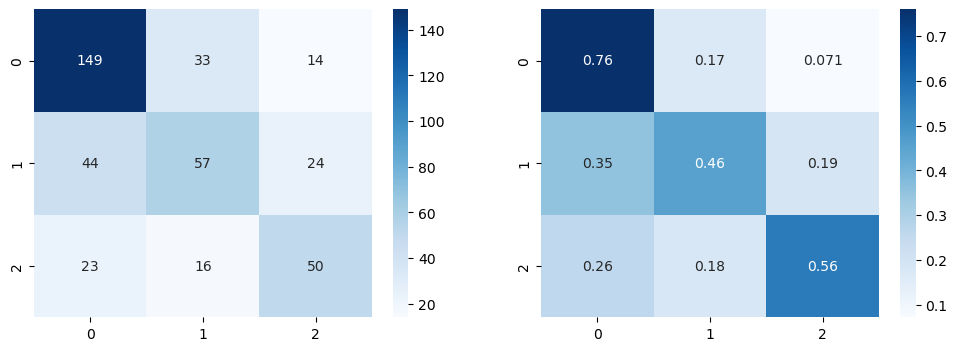

In [5]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=1)

xgb_clf=xgb.XGBClassifier(booster='dart')
xgb_clf.fit(X_train,y_train)

xgb_pred_train=xgb_clf.predict(X_train)
xgb_pred_test=xgb_clf.predict(X_test)

Y_pred = xgb_pred_test

cm0 = confusion_matrix(y_test, Y_pred, normalize="true")
cm1 = confusion_matrix(y_test, Y_pred)

fig = plt.figure(figsize=(12,4))
plt.subplot(121)
sns.heatmap(cm1, annot=True, cmap='Blues',fmt='g')
plt.subplot(122)
sns.heatmap(cm0, annot=True, cmap='Blues')

print('Training Data:')
print(accuracy_score(y_train,xgb_pred_train))
print('Test Data')
print(accuracy_score(y_test,xgb_pred_test))
print('==confusion Matrix==')

print(confusion_matrix(y_test,xgb_pred_test))

print('==classification Report==')

print(classification_report(y_test,xgb_pred_test))

In [6]:
import pandas as pd
from tsfresh.examples.har_dataset import download_har_dataset, load_har_dataset, load_har_classes
from tsfresh import extract_features, extract_relevant_features, select_features
from tsfresh.utilities.dataframe_functions import impute


#X.index = pd.MultiIndex.from_tuples([str(index) for index in X.index])

X = extract_features(master_df, column_id=1) 
X=impute(X)
X=select_features(X, y)


Feature Extraction: 100%|██████████| 50/50 [00:53<00:00,  1.06s/it]
c:\Users\tamim\anaconda3\envs\xgb\Lib\site-packages\tsfresh\utilities\dataframe_functions.py:198: RuntimeWarning: The columns ['0__autocorrelation__lag_0' '0__autocorrelation__lag_1'
 '0__autocorrelation__lag_2' '0__autocorrelation__lag_3'
 '0__autocorrelation__lag_4' '0__autocorrelation__lag_5'
 '0__autocorrelation__lag_6' '0__autocorrelation__lag_7'
 '0__autocorrelation__lag_8' '0__autocorrelation__lag_9'
 '0__query_similarity_count__query_None__threshold_0.0'] did not have any finite values. Filling with zeros.
  warnings.warn(


Training Data:
1.0
Test Data
0.6536585365853659
==confusion Matrix==
[[154  28  14]
 [ 46  54  25]
 [ 11  18  60]]
==classification Report==
              precision    recall  f1-score   support

           0       0.73      0.79      0.76       196
           1       0.54      0.43      0.48       125
           2       0.61      0.67      0.64        89

    accuracy                           0.65       410
   macro avg       0.63      0.63      0.63       410
weighted avg       0.65      0.65      0.65       410



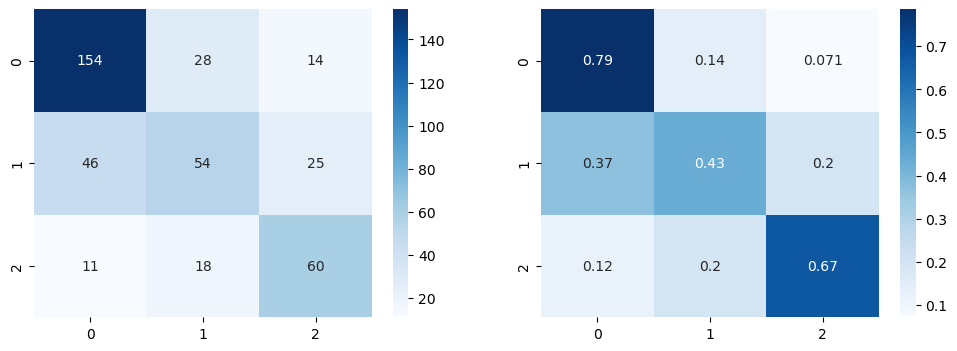

In [7]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=1)

xgb_clf=xgb.XGBClassifier(booster='dart')
xgb_clf.fit(X_train,y_train)

xgb_pred_train=xgb_clf.predict(X_train)
xgb_pred_test=xgb_clf.predict(X_test)

Y_pred = xgb_pred_test

cm0 = confusion_matrix(y_test, Y_pred, normalize="true")
cm1 = confusion_matrix(y_test, Y_pred)

fig = plt.figure(figsize=(12,4))
plt.subplot(121)
sns.heatmap(cm1, annot=True, cmap='Blues',fmt='g')
plt.subplot(122)
sns.heatmap(cm0, annot=True, cmap='Blues')

print('Training Data:')
print(accuracy_score(y_train,xgb_pred_train))
print('Test Data')
print(accuracy_score(y_test,xgb_pred_test))
print('==confusion Matrix==')

print(confusion_matrix(y_test,xgb_pred_test))

print('==classification Report==')

print(classification_report(y_test,xgb_pred_test))